<a href="https://colab.research.google.com/github/nibrunie-universe/arithmetic-value-distribution/blob/main/MultiplierInformationTheory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Inputs, Multiplier Bit Value Distributions & Rounding

We study the probability of each bit of a multiplication result to be set.
We cover different settings (integer and floating-point like values).
We consider the effect of the bit value distribution on the rounding, and in particular on the distribution of the rounding error.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


# Utility function
def generate_uniform_bits(num_samples, num_bits):
    max_val = (1 << num_bits) - 1
    min_val = 0
    clipped_samples = np.random.random_integers(min_val, max_val, size=num_samples)
    return clipped_samples

/tmp/ipykernel_2756/1931845920.py:9: DeprecationWarning: This function is deprecated. Please call randint(0, 1023 + 1) instead
  clipped_samples = np.random.random_integers(min_val, max_val, size=num_samples)


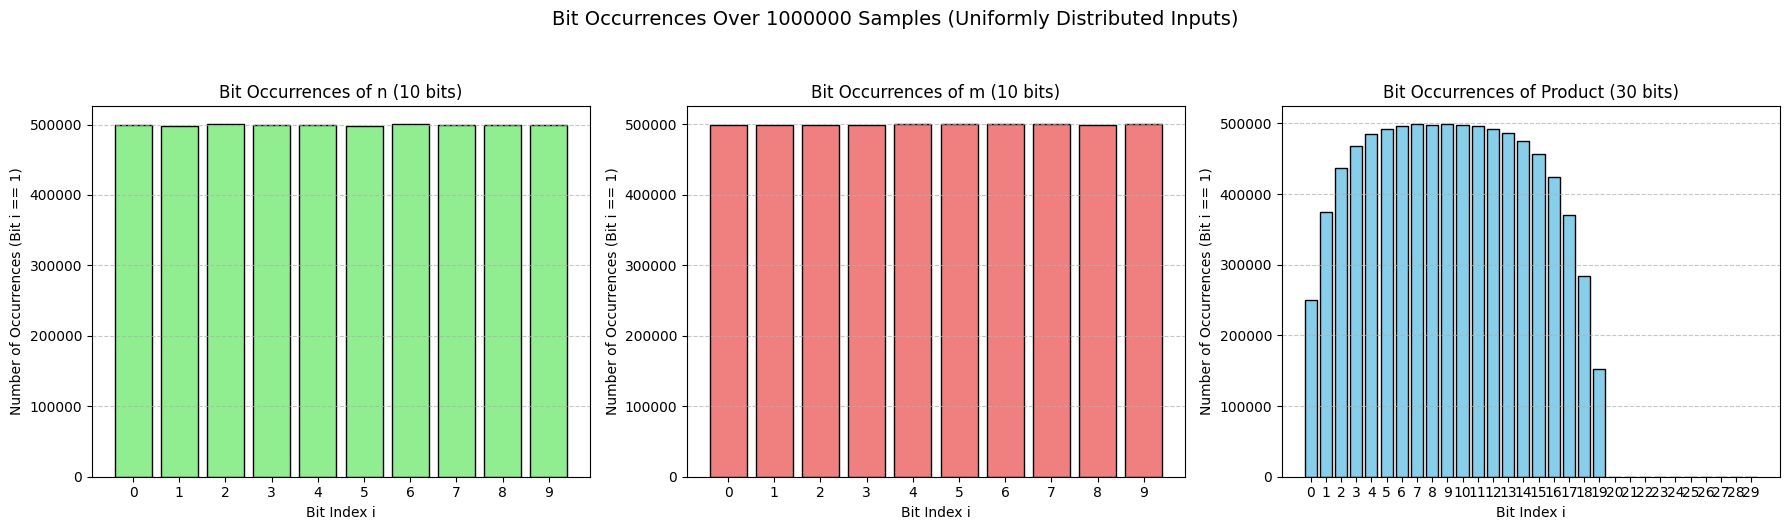

In [2]:


def simulate_dot_product_bit_occurrences_uniform_distribution(n_bits=8, m_bits=8, num_samples=100000, k=4):
    # 1. Generate n-bit and m-bit numbers from uniform distributions
    products = np.zeros(num_samples, dtype=np.int64)
    max_shift = 10
    import math
    log2_k = math.ceil(math.log2(k))

    for _ in range(k):
      n_values = generate_uniform_bits(num_samples, n_bits)
      m_values = generate_uniform_bits(num_samples, m_bits)

      # 2. Perform element-wise multiplication and accumulate
      products += (n_values * m_values)

    # The maximum possible product requires (n_bits + m_bits) bits
    product_bits = n_bits + m_bits + max_shift + log2_k

    # 3. Count occurrences of 1 at each bit index for n, m, and products
    n_bit_counts = np.zeros(n_bits, dtype=np.int64)
    for i in range(n_bits):
        n_bit_counts[i] = np.sum((n_values >> i) & 1)

    m_bit_counts = np.zeros(m_bits, dtype=np.int64)
    for i in range(m_bits):
        m_bit_counts[i] = np.sum((m_values >> i) & 1)

    product_bit_counts = np.zeros(product_bits, dtype=np.int64)
    for i in range(product_bits):
        product_bit_counts[i] = np.sum((products >> i) & 1)

    # 4. Plot the results using subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot for n bits
    axes[0].bar(range(n_bits), n_bit_counts, color='lightgreen', edgecolor='black')
    axes[0].set_xlabel('Bit Index i')
    axes[0].set_ylabel('Number of Occurrences (Bit i == 1)')
    axes[0].set_title(f'Bit Occurrences of n ({n_bits} bits)')
    axes[0].set_xticks(range(n_bits))
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)

    # Plot for m bits
    axes[1].bar(range(m_bits), m_bit_counts, color='lightcoral', edgecolor='black')
    axes[1].set_xlabel('Bit Index i')
    axes[1].set_ylabel('Number of Occurrences (Bit i == 1)')
    axes[1].set_title(f'Bit Occurrences of m ({m_bits} bits)')
    axes[1].set_xticks(range(m_bits))
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)

    # Plot for product bits
    axes[2].bar(range(product_bits), product_bit_counts, color='skyblue', edgecolor='black')
    axes[2].set_xlabel('Bit Index i')
    axes[2].set_ylabel('Number of Occurrences (Bit i == 1)')
    axes[2].set_title(f'Bit Occurrences of Product ({product_bits} bits)')
    axes[2].set_xticks(range(product_bits))
    axes[2].grid(axis='y', linestyle='--', alpha=0.7)

    plt.suptitle(f'Bit Occurrences Over {num_samples} Samples (Uniformly Distributed Inputs)', fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

# Configure parameters and run simulation
simulate_dot_product_bit_occurrences_uniform_distribution(
    n_bits=10,
    m_bits=10,
    num_samples=1000000,
    k=1, # single product
)

Multiplication of two integers with uniformly distributed probability for each bit.
The distributions of each result bit value exhibit an interesting behavior: the highest and lowest bits probability to be set is much lower than 50%, while the medium position bits are close to uniform value probability.

This was expected. For example, if there are 50% of probability for a value to be odd, and it is multiplied by a value with the same odd-valued probability (independent distribution), then the probability of the result to be odd is 25%; since both random samples need to be odd for the result to be odd.

This is not representative of rounding, because the input values are not normalized and the value is uniformly distributed (which may not be the most representative).

/tmp/ipykernel_2756/1931845920.py:9: DeprecationWarning: This function is deprecated. Please call randint(0, 1023 + 1) instead
  clipped_samples = np.random.random_integers(min_val, max_val, size=num_samples)


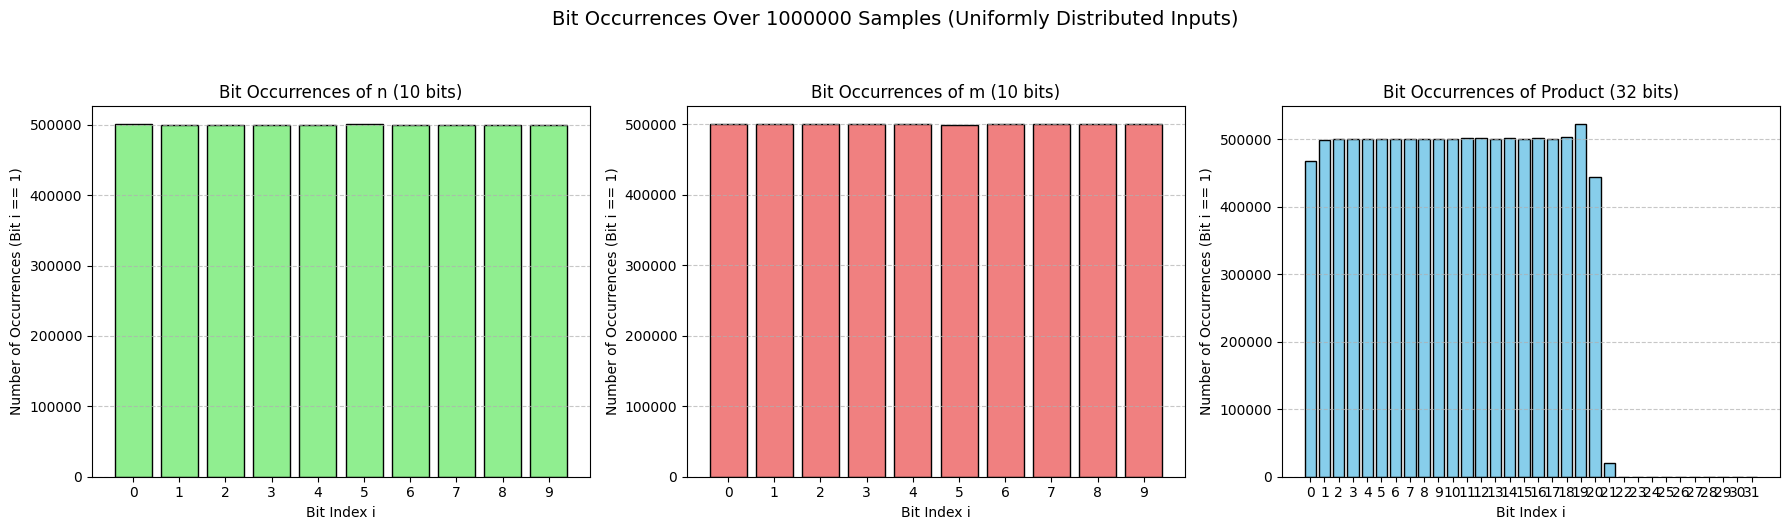

In [3]:
# Running experiment with 4 products accumulated.
# Configure parameters and run simulation.
simulate_dot_product_bit_occurrences_uniform_distribution(
    n_bits=10,
    m_bits=10,
    num_samples=1000000,
    k=4, # 4-element dot product
)

If we now considera 4-element dot product rather than a single product we can see that the distribution of the bit values get smoother.


As we are summing 4 products, we now see non-zero probability of higher bits being set. Once again, this is expected, accumulating 4 18-bit products of random values can lead to 22-bit results.

And the least significant bit probability of being one gets closer to 50%.
To evaluate it theoretically we can consider the probability distribution of the bit vector built by concatenating the LSB of each product to build a 4-bit value L.
If this value has an odd number of bit sets then it indicates an odd result for the 4-element dot product.
We use the single product probabilities for the LSB value of each product: 0 has a probability of 75% and 1 has a probability of 25%.

L ranges between 0 and 15.
0 has a probability of 75% ^ 4 ~ 31.6%
15 (0b1111) has a probability of 25% ^ 4 ~ 0.4%
The probability of each value giving with an odd number of 1 (e.g. 0b1000) is (25%) ^ (#1s) * (75%) ^ (#0s).

In [4]:
prob_odd = 0
for i in range(16):
  num_1s = i.bit_count()
  num_0s = 4 - num_1s
  prob = 0.25 ** num_1s * 0.75 ** num_0s
  if num_1s % 2 == 1:
    prob_odd += prob

print(f"the probability of an odd result in the 4-element dot product is {(prob_odd * 100):.3f}%")

the probability of an odd result in the 4-element dot product is 46.875%


We found a theoretical probability of 46.875%, which seems to be verified emperically by our previous experiment.

## Using normalized product operands

So far we have been using uniformly distributed product operands.
For each operand the number of leading zero n has a probability of 2^(-n-1).
We want to get a bit closer to a floating-point number: our next goal is to determine the random distribution of the value of the bit(s) that are going to be used for rounding (in particular rounding to odd) since their value distribution can impact the distribution of rounding direction.

We start by considering that the operand are normalized significand: integers with the most significant digit always set (no longer random).

We also introduce a random shift between 0 and 10 (included) independent (and uniformly distributed) for each of the product in the dot product sum.

/tmp/ipykernel_2756/3529309431.py:7: DeprecationWarning: This function is deprecated. Please call randint(512, 1023 + 1) instead
  clipped_samples = np.random.random_integers(min_val, max_val, size=num_samples)
/tmp/ipykernel_2756/3529309431.py:21: DeprecationWarning: This function is deprecated. Please call randint(0, 10 + 1) instead
  rand_exps = np.random.random_integers(0, max_shift, size=num_samples)


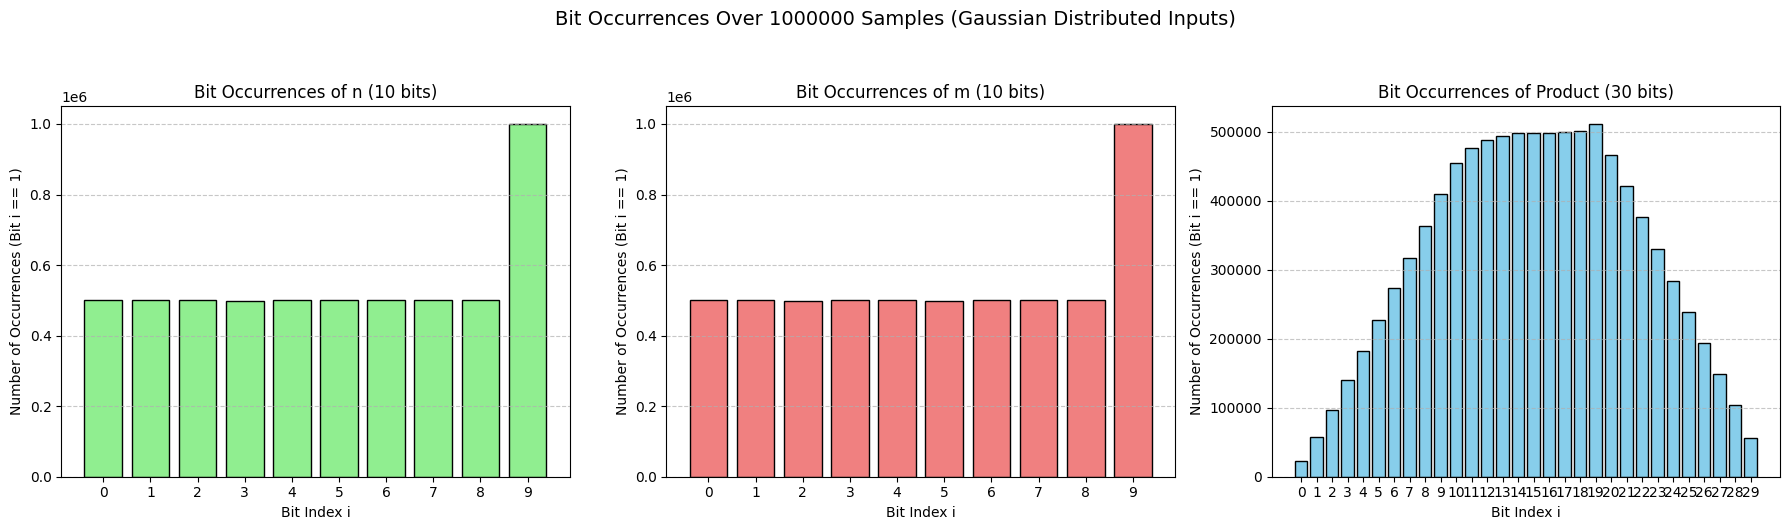

In [5]:

def generate_normalized_uniform_bits(num_samples, num_bits):
    """ generate a set of random samples, each <num_bits> wide
        and between 2^(num_bits -1 ) [included] and 2^(num_bits -1) - 1 [included]
    """
    max_val = (1 << num_bits) - 1
    min_val = (1 << (num_bits - 1))
    clipped_samples = np.random.random_integers(min_val, max_val, size=num_samples)
    return clipped_samples

def simulate_bit_occurrences_normalized_int_dot_product(n_bits=8, m_bits=8, num_samples=100000, k=4):
    # 1. Generate n-bit and m-bit numbers from Gaussian distributions
    products = np.zeros(num_samples, dtype=np.int64)
    max_shift = 10
    import math
    log2_k = math.ceil(math.log2(k))

    for _ in range(k):
      n_values = generate_normalized_uniform_bits(num_samples, n_bits)
      m_values = generate_normalized_uniform_bits(num_samples, m_bits)

      rand_exps = np.random.random_integers(0, max_shift, size=num_samples)

      # 2. Perform element-wise multiplication
      products += (n_values * m_values) << rand_exps

    # The maximum possible product requires (n_bits + m_bits) bits
    product_bits = n_bits + m_bits + max_shift + log2_k

    # 3. Count occurrences of 1 at each bit index for n, m, and products
    n_bit_counts = np.zeros(n_bits, dtype=np.int64)
    for i in range(n_bits):
        n_bit_counts[i] = np.sum((n_values >> i) & 1)

    m_bit_counts = np.zeros(m_bits, dtype=np.int64)
    for i in range(m_bits):
        m_bit_counts[i] = np.sum((m_values >> i) & 1)

    product_bit_counts = np.zeros(product_bits, dtype=np.int64)
    for i in range(product_bits):
        product_bit_counts[i] = np.sum((products >> i) & 1)

    # 4. Plot the results using subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot for n bits
    axes[0].bar(range(n_bits), n_bit_counts, color='lightgreen', edgecolor='black')
    axes[0].set_xlabel('Bit Index i')
    axes[0].set_ylabel('Number of Occurrences (Bit i == 1)')
    axes[0].set_title(f'Bit Occurrences of n ({n_bits} bits)')
    axes[0].set_xticks(range(n_bits))
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)

    # Plot for m bits
    axes[1].bar(range(m_bits), m_bit_counts, color='lightcoral', edgecolor='black')
    axes[1].set_xlabel('Bit Index i')
    axes[1].set_ylabel('Number of Occurrences (Bit i == 1)')
    axes[1].set_title(f'Bit Occurrences of m ({m_bits} bits)')
    axes[1].set_xticks(range(m_bits))
    axes[1].grid(axis='y', linestyle='--', alpha=0.7)

    # Plot for product bits
    axes[2].bar(range(product_bits), product_bit_counts, color='skyblue', edgecolor='black')
    axes[2].set_xlabel('Bit Index i')
    axes[2].set_ylabel('Number of Occurrences (Bit i == 1)')
    axes[2].set_title(f'Bit Occurrences of Product ({product_bits} bits)')
    axes[2].set_xticks(range(product_bits))
    axes[2].grid(axis='y', linestyle='--', alpha=0.7)

    plt.suptitle(f'Bit Occurrences Over {num_samples} Samples (Gaussian Distributed Inputs)', fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

simulate_bit_occurrences_normalized_int_dot_product(
    n_bits=10,
    m_bits=10,
    num_samples=1000000,
    k=1, # single product
)




We can see the peak for bit 9 of both n (left hand side) and m (right hand side) operands: this bit is always one.

The bit distribution of a single product is very regular and combines the single product distribution with the shift value distribution.

/tmp/ipykernel_2756/3529309431.py:7: DeprecationWarning: This function is deprecated. Please call randint(512, 1023 + 1) instead
  clipped_samples = np.random.random_integers(min_val, max_val, size=num_samples)
/tmp/ipykernel_2756/3529309431.py:21: DeprecationWarning: This function is deprecated. Please call randint(0, 10 + 1) instead
  rand_exps = np.random.random_integers(0, max_shift, size=num_samples)


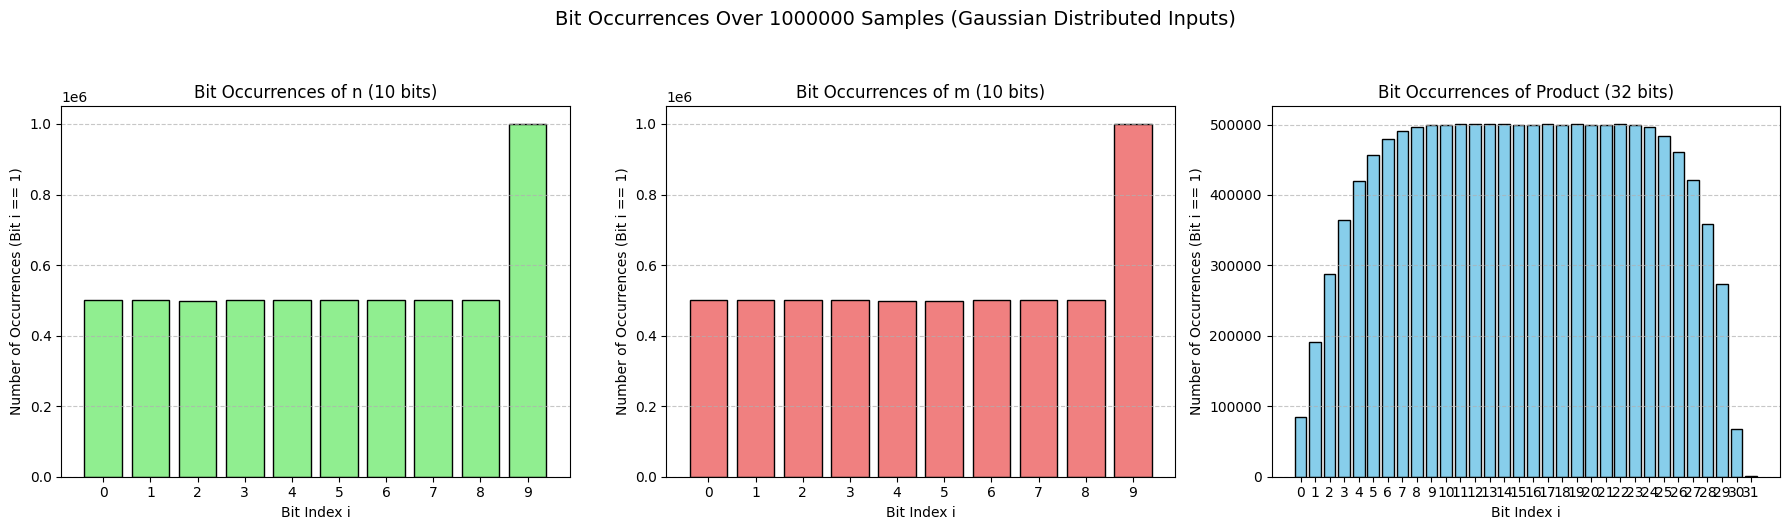

In [6]:

# Configure parameters and run simulation
simulate_bit_occurrences_normalized_int_dot_product(
    n_bits=10,
    m_bits=10,
    num_samples=1000000,
    k=4, # 4-element dot product
)

When we consider 4-product accumulation, the distribution gets more uniform and equality distributed for the bit indices at the center of the range.
The most and least significant bits still exhibits a biased average with the probability of being equal to one decreasing as we get away from the middle bit indices.

But our significand-exponent combined synthetic distributions may not be very realistic.
Next we will study the distribution of dot product result bit elements if we assume normal distribution for the product operand values.

# Random single value generation

Let's try to have a more realistic floating-point number distribution and generate a random number from a gaussian distribution

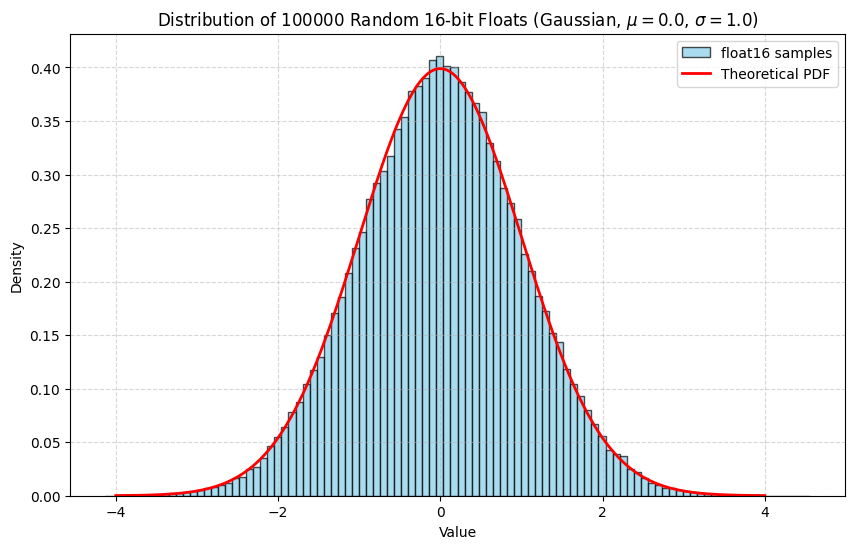

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def generate_gaussian_f16_values(n: int, mu: float, sigma: float):
    # Generate random float16 numbers from a normal (Gaussian) distribution
    vector_float16 = np.random.normal(loc=mu, scale=sigma, size=n).astype(np.float16)
    return vector_float16

# Parameters
n = 100000  # Number of samples
mu = 0.0    # Mean
sigma = 1.0  # Standard deviation

# Generate random float16 numbers from a normal (Gaussian) distribution
vector_float16 = generate_gaussian_f16_values(n, mu, sigma)

# Plot their distribution (repartition)
plt.figure(figsize=(10, 6))
plt.hist(vector_float16, bins=100, density=True, color='skyblue', edgecolor='black', alpha=0.7, label='float16 samples')

# Plot the ideal theoretical Gaussian PDF for comparison
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
pdf = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)
plt.plot(x, pdf, color='red', linewidth=2, label='Theoretical PDF')

plt.title(fr'Distribution of {n} Random 16-bit Floats (Gaussian, $\mu={mu}$, $\sigma={sigma}$)')
plt.xlabel('Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
def transform_f16_values_biased_i64(vector_float16: np.ndarray, bias=2.0**-24):
  """ Transform a vector of float16 values into a vector of biased int64"""
  vector_float32 = vector_float16.astype(np.float32)
  vector_sign = ((1 - np.sign(vector_float32)) / 2).astype(np.int64)
  vector_abs = np.abs(vector_float32)
  vector_int64 = (vector_abs / bias).astype(np.int64)
  vector_int64 = (vector_sign << 63) + vector_int64
  return vector_int64

vector_int64 = transform_f16_values_biased_i64(vector_float16)

# for each bits from 0 to 63, plot how many occurences of value 1 is encountered



In [9]:
import numpy as np
import matplotlib.pyplot as plt

def plot_bit_occurrences(vector_int64, num_bits=64, title='Occurrences of Bit 1 at each position (0 to 63) in vector_int64'):
  # Count occurrences of 1 at each bit index (0 to 63) in vector_int64
  bit_counts = np.zeros(num_bits, dtype=np.int64)

  # We extract the occurrences for each bit index by shifting and masking
  for i in range(num_bits):
      bit_counts[i] = np.sum((vector_int64 >> i) & 1)

  # normalize bit_counts by the number of samples
  normalized_bit_counts = bit_counts / n

  # Plot the occurrences
  plt.figure(figsize=(14, 6))
  plt.bar(range(num_bits), normalized_bit_counts, color='indigo', edgecolor='black', alpha=0.75)
  plt.title(title)
  plt.xlabel('Bit Index')
  plt.ylabel('Number of Occurrences (Bit == 1)')
  plt.xticks(range(0, num_bits, 4))
  plt.grid(axis='y', linestyle='--', alpha=0.5)
  plt.show()
  return bit_counts


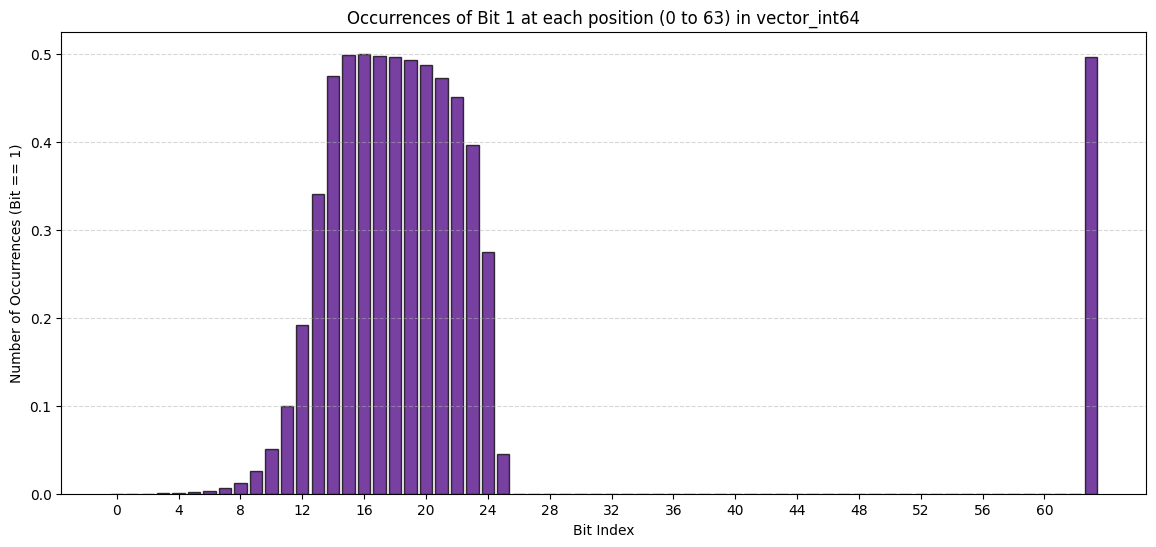

array([    2,    16,    14,    34,    63,   163,   331,   640,  1266,
        2588,  5040, 10003, 19231, 34043, 47516, 49871, 50053, 49770,
       49735, 49358, 48783, 47306, 45084, 39687, 27516,  4504,     4,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
       49644])

In [10]:

num_bits = 64
plot_bit_occurrences(vector_int64, num_bits)

From the Gaussian distribution, we build a representation of the bit values by converting the floating-point values (half precision) to biased 64-bit integers.

The bias for the conversion is chosen to be the smallest possible absolute value a non-zero half precision number can take: 2^-24 (smallest subnormal).

After biasing, the range of an half precision number fits completely in a 64-bit integer. This is not true for the product of two half precision numbers (which would require about 80 bits) or a multi-element dot-product.
So our product and dot product distributions are truncated.

# Random Product Bit Distribution

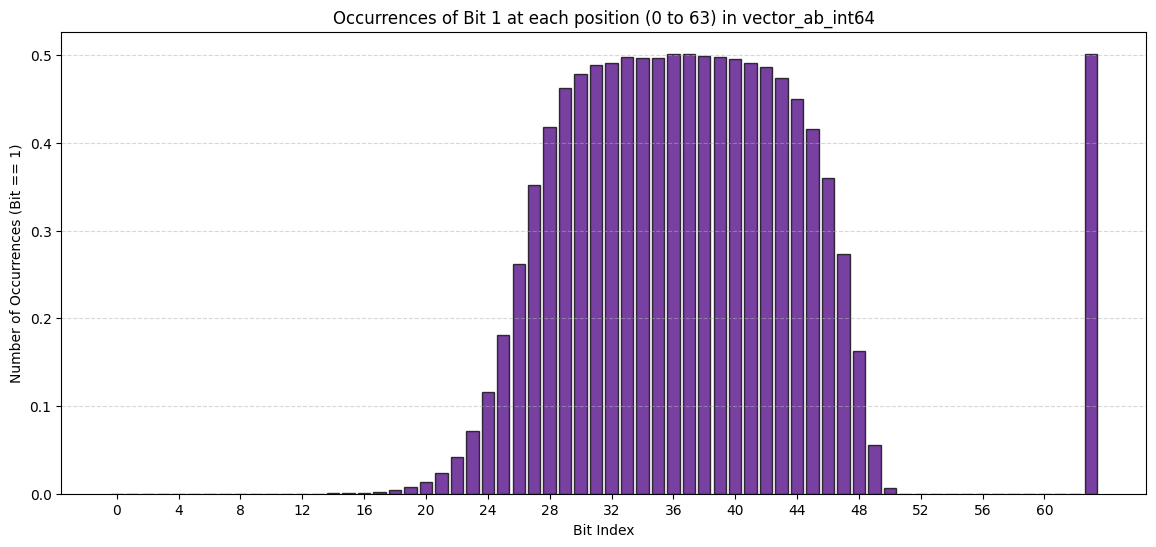

array([    0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     3,     3,     9,    16,    33,    68,   125,   232,
         432,   771,  1318,  2412,  4160,  7133, 11604, 18107, 26201,
       35179, 41862, 46221, 47870, 48904, 49140, 49755, 49730, 49686,
       50077, 50161, 49863, 49738, 49601, 49088, 48595, 47435, 45055,
       41543, 36023, 27285, 16250,  5504,   653,     6,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
       50122])

In [11]:
vector_a_f16 = generate_gaussian_f16_values(n, mu, sigma)
vector_b_f16 = generate_gaussian_f16_values(n, mu, sigma)

vector_ab_f32 = vector_a_f16.astype(np.float32) * vector_b_f16.astype(np.float32)
vector_ab_int64 = transform_f16_values_biased_i64(vector_ab_f32, bias=2.0**-48)

#
plot_bit_occurrences(vector_ab_int64, title='Occurrences of Bit 1 at each position (0 to 63) in vector_ab_int64')

# Random Dot Product Bit Distribution (4-element)

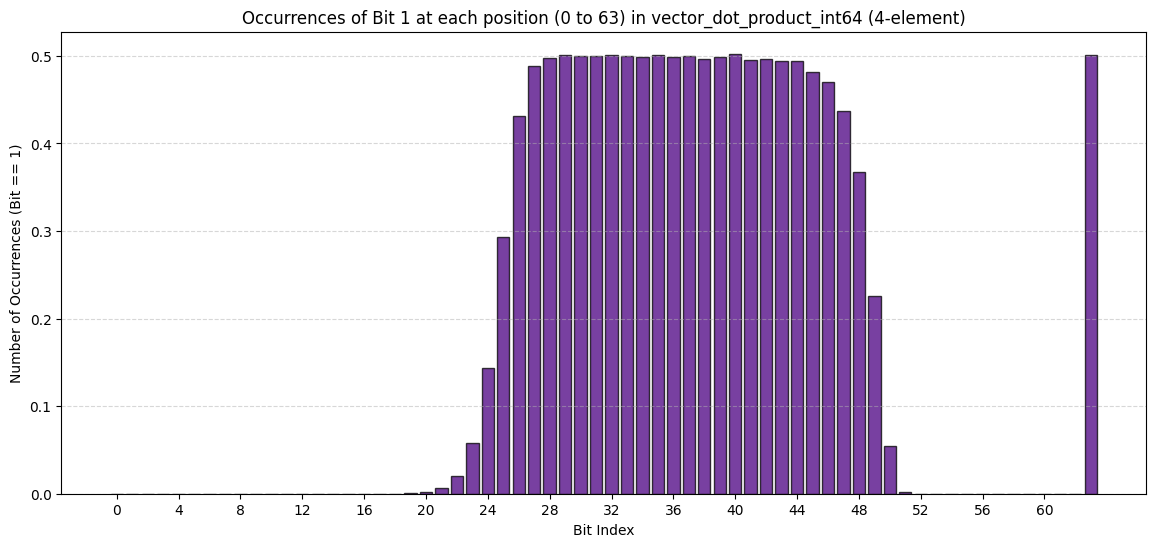

array([    0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     2,     5,
          15,    52,   177,   631,  1996,  5746, 14363, 29325, 43152,
       48885, 49766, 50139, 49975, 49963, 50055, 49930, 49900, 50082,
       49877, 49985, 49606, 49899, 50246, 49564, 49671, 49461, 49360,
       48213, 47006, 43681, 36761, 22632,  5403,   182,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
       50114])

In [12]:
k = 4
vector_dot_product = np.zeros(n, dtype=np.float64)
for _ in range(k):
  vector_a_f16 = generate_gaussian_f16_values(n, mu, sigma)
  vector_b_f16 = generate_gaussian_f16_values(n, mu, sigma)

  vector_ab_f32 = vector_a_f16.astype(np.float32) * vector_b_f16.astype(np.float32)
  vector_dot_product += vector_ab_f32.astype(np.float64)

vector_dot_product_int64 = transform_f16_values_biased_i64(vector_dot_product.astype(np.float32), bias=2.0**-48)

#
plot_bit_occurrences(vector_dot_product_int64, title='Occurrences of Bit 1 at each position (0 to 63) in vector_dot_product_int64 (4-element)')

## Random Bit Distribution for 16-element Dot Product

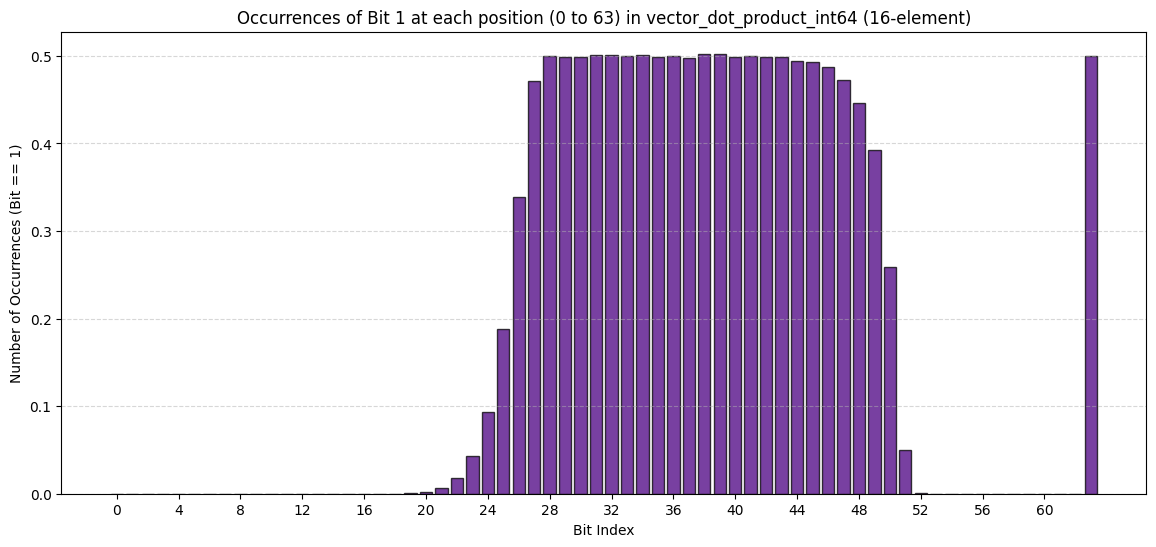

array([    0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     2,     4,
          21,    69,   212,   657,  1765,  4329,  9284, 18863, 33852,
       47153, 49954, 49832, 49827, 50131, 50146, 49937, 50070, 49904,
       50024, 49751, 50248, 50190, 49837, 50002, 49928, 49899, 49440,
       49336, 48715, 47210, 44669, 39230, 25926,  4938,    38,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
       49985])

In [13]:
k = 16
vector_dot_product = np.zeros(n, dtype=np.float64)
for _ in range(k):
  vector_a_f16 = generate_gaussian_f16_values(n, mu, sigma)
  vector_b_f16 = generate_gaussian_f16_values(n, mu, sigma)

  vector_ab_f32 = vector_a_f16.astype(np.float32) * vector_b_f16.astype(np.float32)
  vector_dot_product += vector_ab_f32.astype(np.float64)

vector_dot_product_int64 = transform_f16_values_biased_i64(vector_dot_product.astype(np.float32), bias=2.0**-48)

#
plot_bit_occurrences(vector_dot_product_int64, title='Occurrences of Bit 1 at each position (0 to 63) in vector_dot_product_int64 (16-element)')

# Distribution of the rounding bit values

Let us consider rounding to odd. In rounding to odd, the direction of rounding depends on two things: the value of the rounding bit (the bit which correspond to the least significand bit of the unrounded significand) and the trailing (sometimes called sticky) bits, that is the bits whose weigth is smaller than the rounding bit.

If all the trailing/sticky bits are zero, the result is exact and the rounded value is equal to the unrounded result.

If any of the trailing/sticky bit is non-zero, the rounding bit gets force to one. This corresponds to rounding away from zero when the rounding bit is zero (even unrounded significand) else rounding towards zero when the rounding bit is one (odd unrounded significand).

vector_dot_product_int64=[ 516385629274112  673347725688832 1447222247948288  118384414949376
  446946309308416 1324891781464064   68364550537216  756333741604864
 1086573978320896 1113756826337280]
vector_dot_product_int64=[15 14 13 17 15 13 18 14 14 14]
vector_dot_product_i64_normalized=[-1525819773655449600 -7414614936023728128 -6591099418517176320
 -2929862037464940544 -3801207410291376128 -7593230599955939328
  -525387337681600512 -6054972051255459840  -644316012899991552
  -198952230999556096]


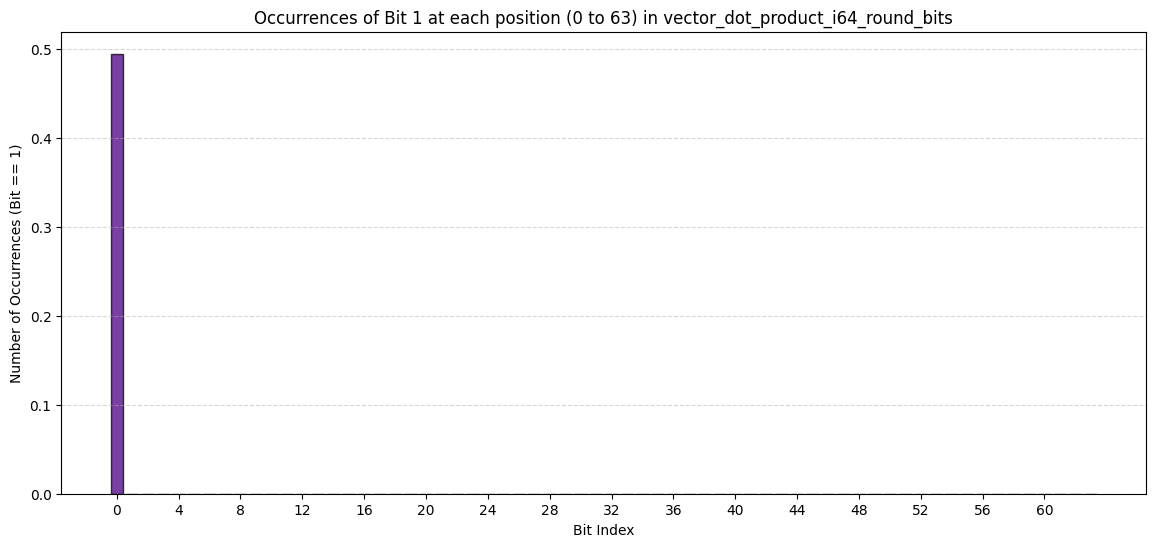

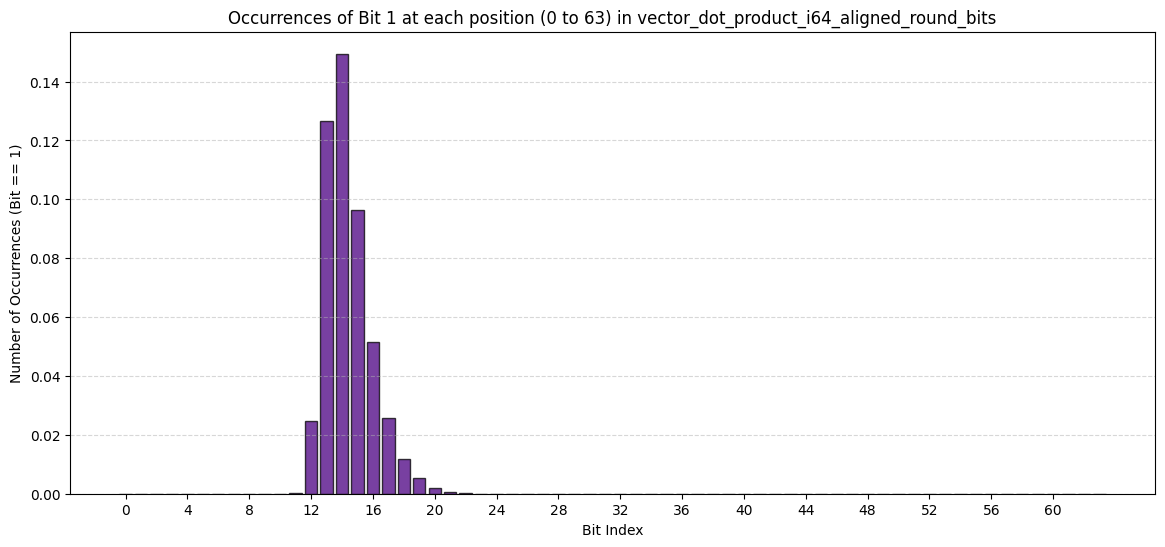

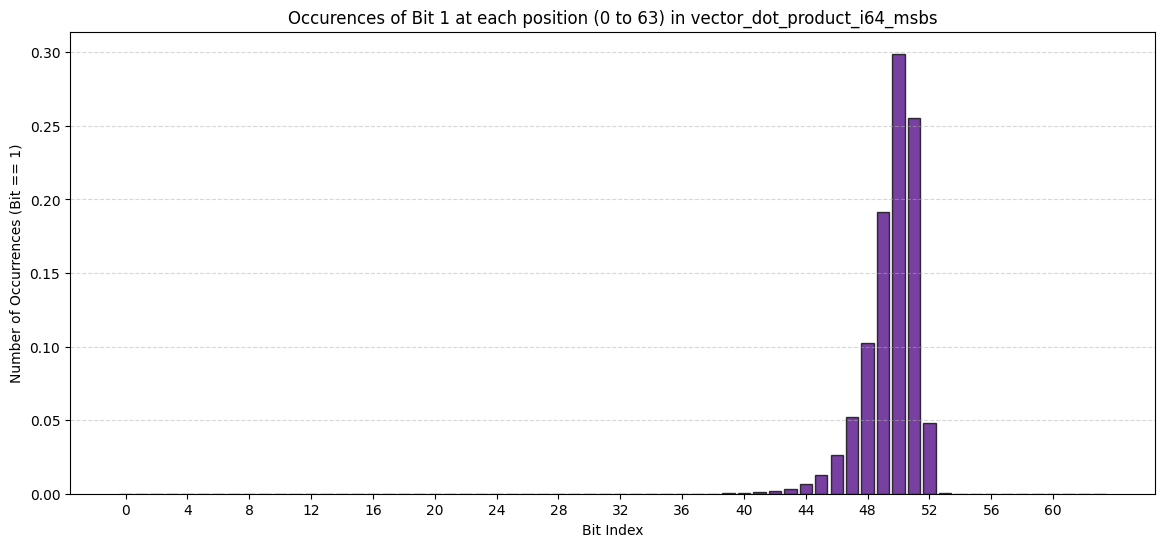

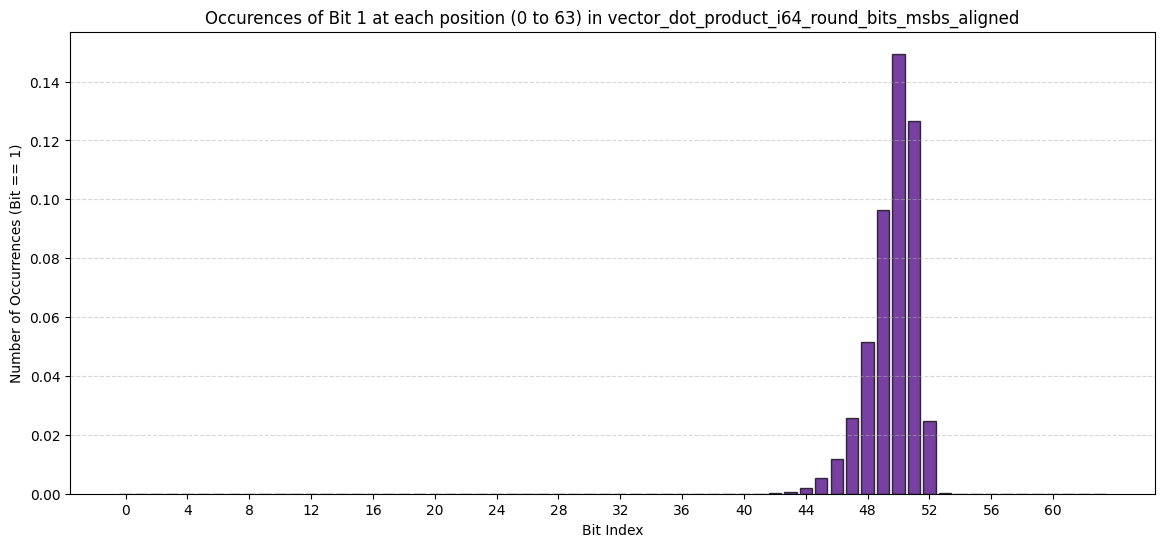

In [14]:

k = 16
vector_dot_product = np.zeros(n, dtype=np.float64)
for _ in range(k):
  vector_a_f16 = generate_gaussian_f16_values(n, mu, sigma)
  vector_b_f16 = generate_gaussian_f16_values(n, mu, sigma)

  vector_ab_f32 = vector_a_f16.astype(np.float32) * vector_b_f16.astype(np.float32)
  vector_dot_product += vector_ab_f32.astype(np.float64)


# computing absolute value to exclude the sign from the study (for now)
vector_dot_product = np.abs(vector_dot_product)

vector_dot_product_int64 = transform_f16_values_biased_i64(vector_dot_product.astype(np.float32), bias=2.0**-48)
print(f"vector_dot_product_int64={vector_dot_product_int64[:10]}")

# Now that we have converted the dot product to int64 we extra the leading zero count for each of them

# We build a vector function to extract the leading zero count of each element
def count_leading_zero_bits(val, width=64):
  _, bit_lengths = np.frexp(val)
  return width - bit_lengths
vec_clz = np.vectorize(count_leading_zero_bits)

vector_dot_product_int64_lzc = vec_clz(vector_dot_product_int64)
print(f"vector_dot_product_int64={vector_dot_product_int64_lzc[:10]}")
vector_dot_product_i64_normalized = vector_dot_product_int64 << vector_dot_product_int64_lzc
print(f"vector_dot_product_i64_normalized={vector_dot_product_i64_normalized[:10]}")

# extracting the value of the round bit
precision = 24
vector_dot_product_i64_round_bits = (vector_dot_product_i64_normalized >> (64 - (precision - 1))) & 1

#
plot_bit_occurrences(vector_dot_product_i64_round_bits, title='Occurrences of Bit 1 at each position (0 to 63) in vector_dot_product_i64_round_bits')

vector_dot_product_i64_aligned_round_bits = vector_dot_product_i64_round_bits << vector_dot_product_int64_lzc
bit_counts_round_bits = plot_bit_occurrences(
    vector_dot_product_i64_aligned_round_bits,
    title='Occurrences of Bit 1 at each position (0 to 63) in vector_dot_product_i64_aligned_round_bits'
)

vector_dot_product_i64_msbs = np.ones(n, dtype=np.int64) << (64 - vector_dot_product_int64_lzc)
bit_counts_msbs = plot_bit_occurrences(
    vector_dot_product_i64_msbs,
    title='Occurences of Bit 1 at each position (0 to 63) in vector_dot_product_i64_msbs'
)

# position the round bits such that it appears at exactly the same position as the element MSBs
vector_dot_product_i64_round_bits_msbs_aligned = vector_dot_product_i64_round_bits  << (64 - vector_dot_product_int64_lzc)
bit_counts_round_bits_msbs_aligned = plot_bit_occurrences(
    vector_dot_product_i64_round_bits_msbs_aligned,
    title='Occurences of Bit 1 at each position (0 to 63) in vector_dot_product_i64_round_bits_msbs_aligned'
)

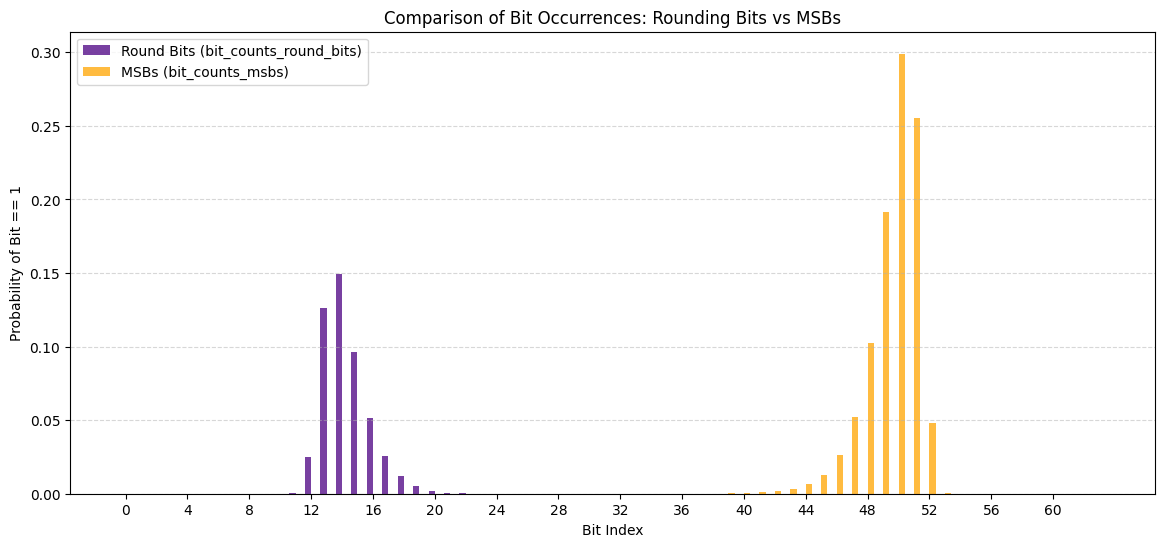

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Safely compute the bit counts from the existing arrays in the kernel
bit_counts_round_bits = np.zeros(64, dtype=np.int64)
bit_counts_msbs = np.zeros(64, dtype=np.int64)

for i in range(64):
    bit_counts_round_bits[i] = np.sum((vector_dot_product_i64_aligned_round_bits >> i) & 1)
    bit_counts_msbs[i] = np.sum((vector_dot_product_i64_msbs >> i) & 1)

# Normalize the bit counts for plotting
normalized_round_bits = bit_counts_round_bits / n
normalized_msbs = bit_counts_msbs / n

# Create a plot comparing both distributions
plt.figure(figsize=(14, 6))
plt.bar(np.arange(64) - 0.2, normalized_round_bits, width=0.4, color='indigo', alpha=0.75, label='Round Bits (bit_counts_round_bits)')
plt.bar(np.arange(64) + 0.2, normalized_msbs, width=0.4, color='orange', alpha=0.75, label='MSBs (bit_counts_msbs)')

plt.title('Comparison of Bit Occurrences: Rounding Bits vs MSBs')
plt.xlabel('Bit Index')
plt.ylabel('Probability of Bit == 1')
plt.xticks(range(0, 64, 4))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.show()

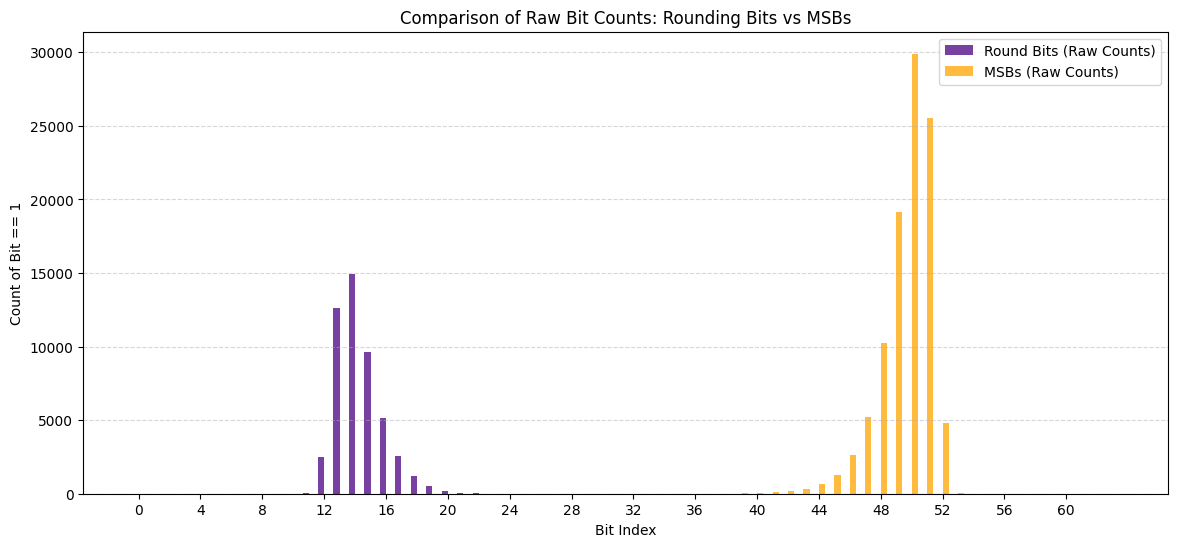

In [16]:
import matplotlib.pyplot as plt
import numpy as np


# Plot the raw counts directly to compare distributions without normalization
plt.figure(figsize=(14, 6))
plt.bar(np.arange(64) - 0.2, bit_counts_round_bits, width=0.4, color='indigo', alpha=0.75, label='Round Bits (Raw Counts)')
plt.bar(np.arange(64) + 0.2, bit_counts_msbs, width=0.4, color='orange', alpha=0.75, label='MSBs (Raw Counts)')

plt.title('Comparison of Raw Bit Counts: Rounding Bits vs MSBs')
plt.xlabel('Bit Index')
plt.ylabel('Count of Bit == 1')
plt.xticks(range(0, 64, 4))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.show()

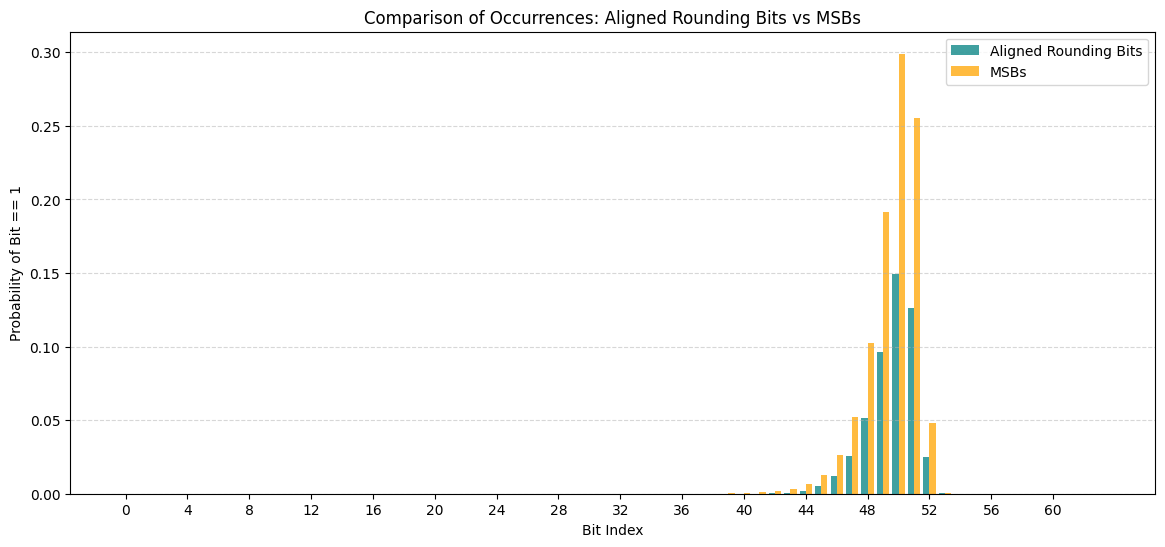

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Normalize the counts by the number of samples n
normalized_round_bits_aligned = bit_counts_round_bits_msbs_aligned / n
normalized_msbs = bit_counts_msbs / n

plt.figure(figsize=(14, 6))
plt.bar(np.arange(64) - 0.2, normalized_round_bits_aligned, width=0.4, color='teal', alpha=0.75, label='Aligned Rounding Bits')
plt.bar(np.arange(64) + 0.2, normalized_msbs, width=0.4, color='orange', alpha=0.75, label='MSBs')

plt.title('Comparison of Occurrences: Aligned Rounding Bits vs MSBs')
plt.xlabel('Bit Index')
plt.ylabel('Probability of Bit == 1')
plt.xticks(range(0, 64, 4))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.show()

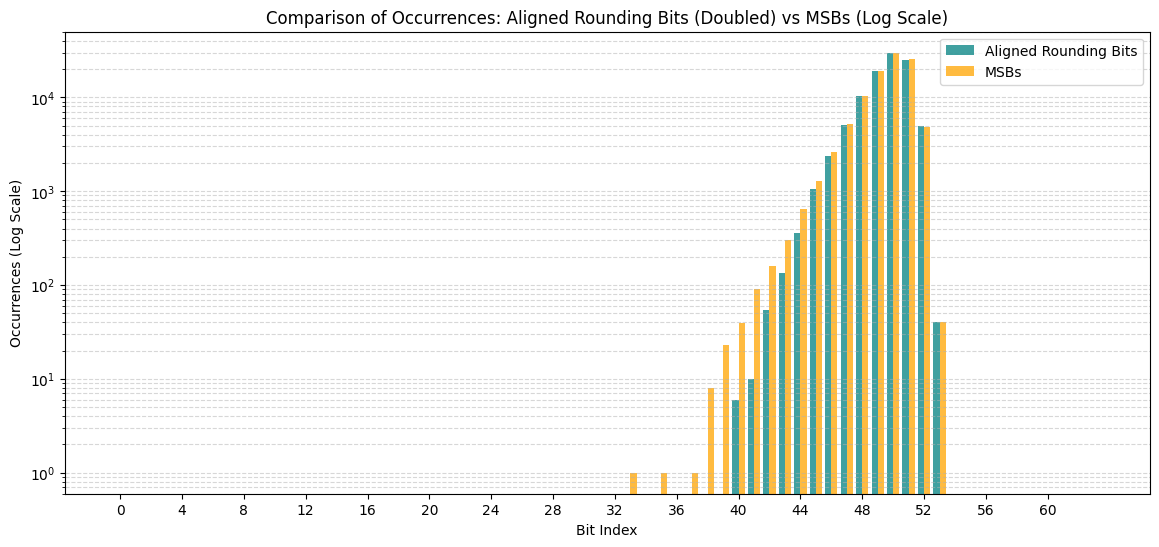

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Double the round bit counts (to allow for easier comparison with msb counts)
normalized_round_bits_aligned = bit_counts_round_bits_msbs_aligned * 2
normalized_msbs = bit_counts_msbs

plt.figure(figsize=(14, 6))
plt.bar(np.arange(64) - 0.2, normalized_round_bits_aligned, width=0.4, color='teal', alpha=0.75, label='Aligned Rounding Bits')
plt.bar(np.arange(64) + 0.2, normalized_msbs, width=0.4, color='orange', alpha=0.75, label='MSBs')

plt.yscale('log')
plt.title('Comparison of Occurrences: Aligned Rounding Bits (Doubled) vs MSBs (Log Scale)')
plt.xlabel('Bit Index')
plt.ylabel('Occurrences (Log Scale)')
plt.xticks(range(0, 64, 4))
plt.grid(axis='y', linestyle='--', alpha=0.5, which='both')
plt.legend()
plt.show()

The absolute plot above can help better discover any imbalance.
Before counting occurences of 1s, the round bit has been aligned with its MSB.
So a MSB count increment at bit index n means that the MSB has weigth/index n; and a round bit increment at bit index n means that the round bit has weighth (n - precision).
Furthermore, the round bit counts have been doubled since the default count only represent the occurence of 1s.
Thus if the round bit count matches the MSB count for a given index, it indicates that the round bit was equal to 1 exactly half of the time when the value's MSB has this particular index.
If the round bit count exceeds the MSB count, then the rounding bit value is imbalanced in favor of more 1s.
If the round bit count trails the MSB count, then the rounding bit value is imbalanced in favor of a higher probability of the round bit being 0.

The plot present the imbalance per bit index.
What about the overall imbalance?

In [17]:
# Ratio of round bits over msb position
bit_counts_round_bits_ratio = bit_counts_round_bits_msbs_aligned / bit_counts_msbs

/tmp/ipykernel_2756/1175038382.py:2: RuntimeWarning: invalid value encountered in divide
  bit_counts_round_bits_ratio = bit_counts_round_bits_msbs_aligned / bit_counts_msbs


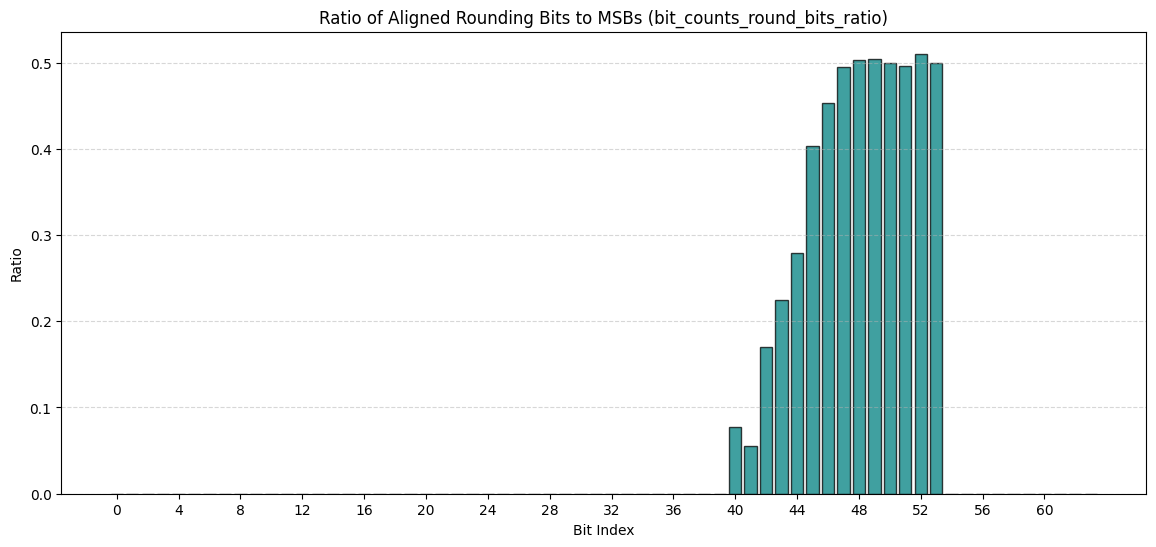

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate the ratio safely, avoiding division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    bit_counts_round_bits_ratio = np.true_divide(bit_counts_round_bits_msbs_aligned, bit_counts_msbs)
    safe_ratio = np.nan_to_num(bit_counts_round_bits_ratio, nan=0.0, posinf=0.0, neginf=0.0)

plt.figure(figsize=(14, 6))
plt.bar(range(64), safe_ratio, color='teal', edgecolor='black', alpha=0.75)
plt.title('Ratio 1s in Aligned Rounding Bits to MSBs (bit_counts_round_bits_ratio)')
plt.xlabel('Bit Index')
plt.ylabel('Ratio')
plt.xticks(range(0, 64, 4))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [22]:
total_round_bits = bit_counts_round_bits_msbs_aligned.sum()
total_msbs = bit_counts_msbs.sum()

percentage = (total_round_bits / total_msbs) * 100
print(f"Total occurrences in aligned rounding bits: {total_round_bits}")
print(f"Total occurrences in MSBs: {total_msbs}")
print(f"Ratio: {percentage:.3f}%")

Total occurrences in aligned rounding bits: 49438
Total occurrences in MSBs: 100000
Ratio: 49.438%


Is this slight bias idiosyncratic to this run or is it an intrinsic property of the distribution, operation and rounding algorithm?

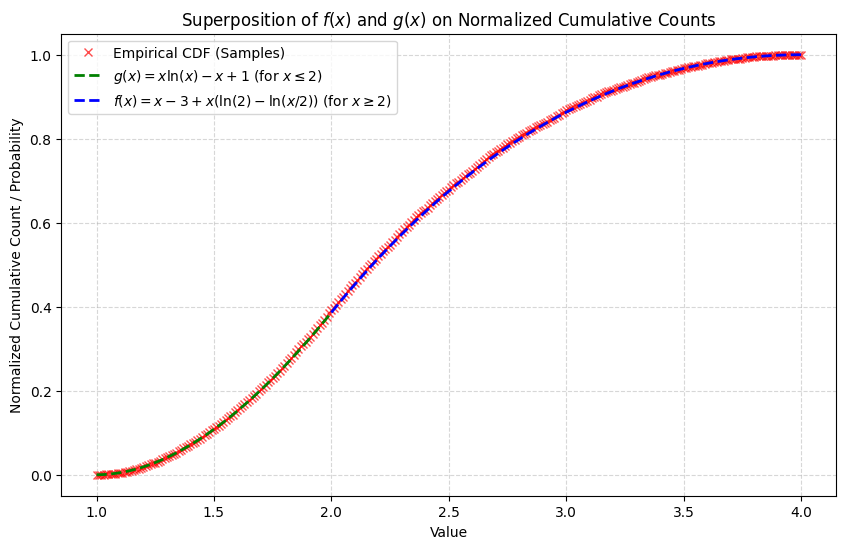

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Define the analytical functions
def f(x):
    return x - 3 + x * (np.log(2) - np.log(x / 2.0))

def g(x):
    return x * np.log(x) - x + 1

# Define n explicitly in case kernel was restarted
n = 10000

# Generate two sets of n random samples from U(1, 2)
samples1 = np.random.uniform(1.0, 2.0, size=n)
samples2 = np.random.uniform(1.0, 2.0, size=n)

# Combine the samples (sum them to span the range up to 4)
combined_values = samples1 * samples2

# Define the bins/thresholds from 1 to 4 with a step of 0.01
thresholds = np.arange(1.0, 4.01, 0.01)

# Compute cumulative counts for each threshold
cumulative_counts = [np.sum(combined_values <= t) for t in thresholds]

# Normalized cumulative count from the uniform product experiment
normalized_cumulative_counts = np.array(cumulative_counts) / n

plt.figure(figsize=(10, 6))
# Plot empirical cumulative distribution as red crosses
plt.plot(thresholds, normalized_cumulative_counts, 'rx', label='Empirical CDF (Samples)', alpha=0.7)

# Define correct piecewise domains
mask_g = thresholds <= 2.0
mask_f = thresholds >= 2.0

# Superpose analytical curves only over their valid domains
plt.plot(thresholds[mask_g], g(thresholds[mask_g]), 'g--', linewidth=2, label=r'$g(x) = x\text{ln}(x) - x + 1$ (for $x \leq 2$)')
plt.plot(thresholds[mask_f], f(thresholds[mask_f]), 'b--', linewidth=2, label=r'$f(x) = x - 3 + x(\text{ln}(2) - \text{ln}(x/2))$ (for $x \geq 2$)')

plt.title('Superposition of $f(x)$ and $g(x)$ on Normalized Cumulative Counts')
plt.xlabel('Value')
plt.ylabel('Normalized Cumulative Count / Probability')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

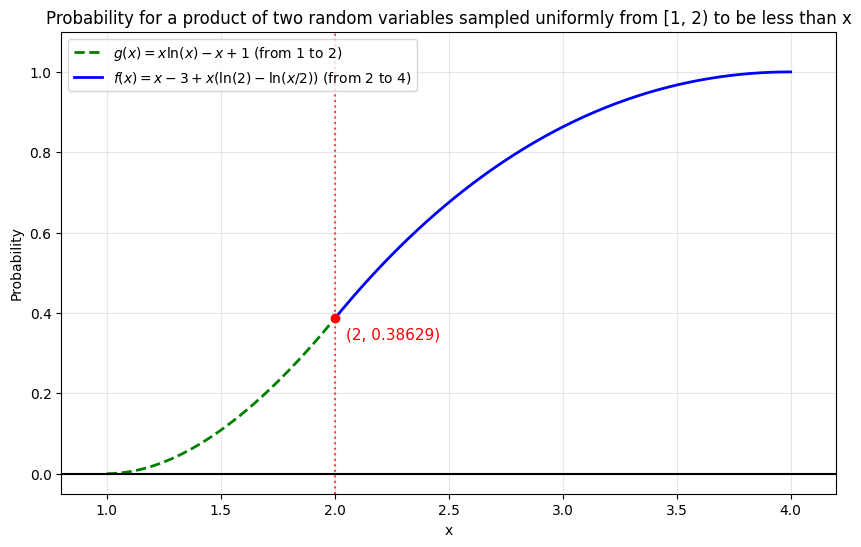

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Define the functions
def g(x):
    return x * np.log(x) - x + 1

def f(x):
    return x - 3 + x * (np.log(2) - np.log(x/2))

# Generate x values for the specific domains
x_g = np.linspace(1, 2, 400)
x_f = np.linspace(2, 4, 400)

# Create the plot
plt.figure(figsize=(10, 6))

# Plot Function 1 (g(x))
plt.plot(x_g, g(x_g), color='green', linestyle='--', linewidth=2,
         label=r'$g(x) = x \ln(x) - x + 1$ (from 1 to 2)')

# Plot Function 2 (f(x))
plt.plot(x_f, f(x_f), color='blue', linestyle='-', linewidth=2,
         label=r'$f(x) = x - 3 + x(\ln(2) - \ln(x/2))$ (from 2 to 4)')

# Markers & Annotations
intersection_y = 0.38629
plt.axvline(x=2, color='red', linestyle=':', alpha=0.7)
plt.plot(2, intersection_y, 'ro') # Red dot
plt.text(2.05, intersection_y - 0.05, f'(2, {intersection_y})', color='red', fontsize=11)

# Axes & Styling
plt.xlim(0.8, 4.2)
plt.ylim(-0.05, 1.1)
plt.axhline(0, color='black', linewidth=1.5) # Solid black line at y=0
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

# Title and Labels
plt.title("Probability for a product of two random variables sampled uniformly from [1, 2) to be less than x")
plt.xlabel("x")
plt.ylabel("Probability")

# Display the graph
plt.show()